# M5 Demand Forecasting - Notebook 04: Inventory simulation

**Question:** does a better forecast actually save money? We turn forecasts into ordering decisions, simulate what would have happened, and compare **stockouts, inventory and cost** for each forecast.

Run `python -m src.run_inventory` first (after notebooks 02 and 03).

**The most important caveat:** M5 contains **no stock levels, costs or lead times**. This is a *simulation under stated assumptions*, not a measurement of Walmart's real savings. The assumptions are listed in section 1 and can be changed in `src/config.py`. The notebook therefore leads with comparisons that do **not** depend on cost guesses (the service-vs-inventory trade-off), and shows cost results together with a sensitivity check.

**The policy (periodic review, order-up-to)**
- Every `R` days the planner orders enough to bring stock (on hand + on order) up to `S`.
- `S` is the quantile of demand over the next `L + R` days that gives the target service level, where `L` is the lead time.
- Demand over that period is modelled with a negative binomial distribution: the mean comes from the forecast, and the extra variance is measured from that **same method's own past forecast errors**. A better forecast has smaller errors, so it needs less safety stock for the same service.
- Sales that cannot be served are lost (no backorders). An **oracle** that knows the future shows the best any forecast could ever do.

**Sections:** 1) Assumptions, 2) Service vs inventory trade-off, 3) Equal-service comparison, 4) Cost at the target service level, 5) By segment, 6) Sensitivity to the cost assumptions, 7) Replenishment plan (for the web), 8) Key findings

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
from src.viz import show_table, save_table

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
config.FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

T = config.TABLES_DIR
need = ["inventory_results.csv", "inventory_assumptions.csv", "inventory_calibration.csv", "replenishment_plan.csv"]
missing = [f for f in need if not (T / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing} in {T}.\nRun first in a terminal: python -m src.run_lgbm and then python -m src.run_inventory")

res = pd.read_csv(T / "inventory_results.csv")
assump = pd.read_csv(T / "inventory_assumptions.csv")
calib = pd.read_csv(T / "inventory_calibration.csv")
plan = pd.read_csv(T / "replenishment_plan.csv")
TARGET = float(assump.loc[assump["assumption"] == "target_service_level", "value"].iloc[0])
COLORS = {"lightgbm": "#c44e52", "moving_avg_28d": "#4c72b0", "croston_sba": "#55a868", "seasonal_avg_4w": "#8172b3"}

def at_target(df):
    return df[np.isclose(df["alpha"], TARGET) | df["alpha"].isna()]

def with_costs(df, ratio=None, rate=None, pen=None):
    ratio = config.INV_COST_RATIO if ratio is None else ratio
    rate = config.INV_HOLDING_RATE if rate is None else rate
    pen = config.INV_STOCKOUT_PENALTY if pen is None else pen
    d = df.copy()
    d["fill_rate_units"] = d["sold_units"] / d["demand_units"]
    d["fill_rate_revenue"] = 1 - d["lost_rev"] / d["demand_rev"]
    d["avg_inventory_value"] = d["inv_rev_days"] * ratio / d["sim_days"]
    d["holding_cost"] = d["inv_rev_days"] * ratio * rate / 365
    d["stockout_cost"] = d["lost_rev"] * ((1 - ratio) + pen)
    d["total_cost"] = d["holding_cost"] + d["stockout_cost"]
    return d

print(f"{int(res['n_series'].max()):,} series simulated | target service level {TARGET:.0%}")

12,185 series simulated | target service level 95%


## 1. Assumptions

Everything the results depend on. **Report the results together with these assumptions.**

In [2]:
cost_assump = pd.DataFrame([
    ("unit cost as share of price", config.INV_COST_RATIO, "gross margin = 1 - this"),
    ("yearly holding cost rate", config.INV_HOLDING_RATE, "capital, storage, shrink, as a share of inventory value"),
    ("extra stockout penalty", config.INV_STOCKOUT_PENALTY, "goodwill cost per lost unit as a share of price; 0 = lost margin only"),
], columns=["assumption", "value", "meaning"])
print("Simulation setup (from run_inventory):")
show_table(assump)
print("Cost assumptions (from config.py, changeable without re-running the simulation):")
show_table(cost_assump)

Simulation setup (from run_inventory):


Cost assumptions (from config.py, changeable without re-running the simulation):


## 2. Service vs inventory trade-off

This view needs **no cost assumptions**. Each line shows, for one forecast, how much inventory is needed to reach a given service level. The service level is tried from 80% to 99%, and the target level is circled. A line that is **higher and further left** is better: more demand served with less stock. The star is the oracle that knows the future.

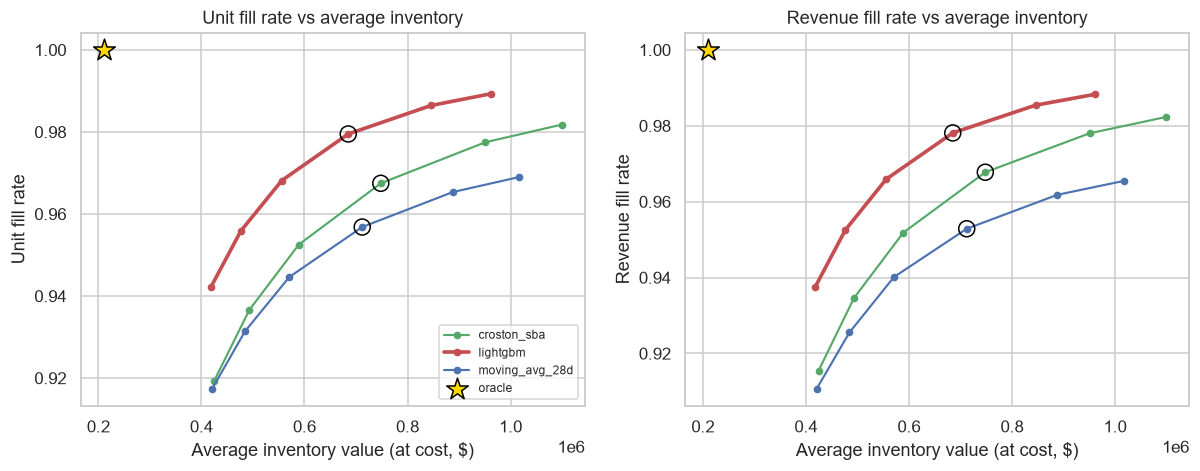

In [3]:
r = with_costs(res[res["level"] == "all"])
curve = r[r["method"] != "oracle"].sort_values(["method", "alpha"])
orc = r[r["method"] == "oracle"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, ycol, title in zip(axes, ["fill_rate_units", "fill_rate_revenue"], ["Unit fill rate", "Revenue fill rate"]):
    for m, g in curve.groupby("method"):
        ax.plot(g["avg_inventory_value"], g[ycol], marker="o", ms=4, lw=2.4 if m == "lightgbm" else 1.4,
                color=COLORS.get(m), label=m)
        t = g[np.isclose(g["alpha"], TARGET)]
        ax.scatter(t["avg_inventory_value"], t[ycol], s=110, facecolor="none", edgecolor="black", zorder=5)
    ax.scatter(orc["avg_inventory_value"], orc[ycol], marker="*", s=220, color="gold", edgecolor="black", zorder=6, label="oracle")
    ax.set(title=f"{title} vs average inventory", xlabel="Average inventory value (at cost, $)", ylabel=title)
axes[0].legend(fontsize=8, loc="lower right")
save(fig, "26_service_vs_inventory"); plt.show()

## 3. Equal-service comparison

The forecasts do not reach exactly the same service level at the same setting, so comparing their costs directly can mislead. A fairer question: **to reach the same service level as the best baseline, how much inventory does LightGBM need?** For each service setting, we take the baseline's result and read off, from the LightGBM curve, the inventory needed for the same revenue fill rate (linear interpolation). We also read the opposite: with the same inventory, how much more demand can LightGBM serve?

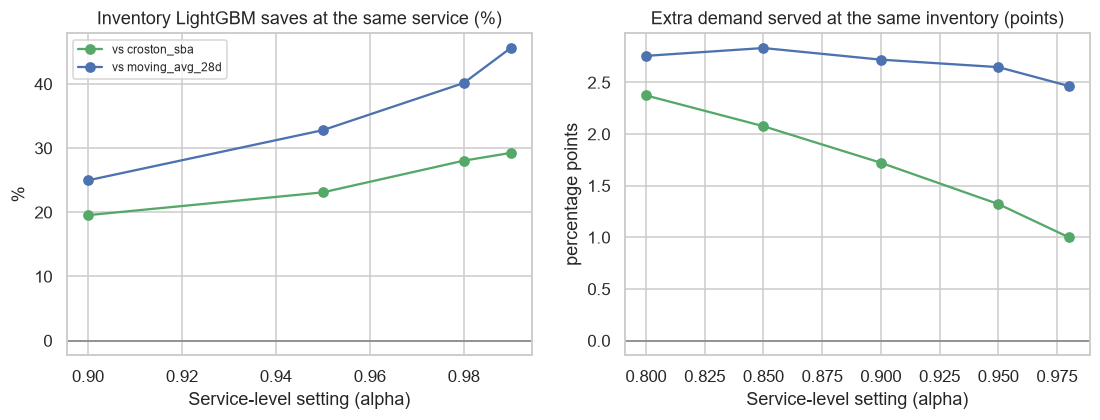

In [4]:
base_methods = [m for m in curve["method"].unique() if m != "lightgbm"]

def interp_curve(g, x_name, y_name, x0):
    g = g.sort_values(x_name)
    xs = np.maximum.accumulate(g[x_name].to_numpy())
    ys = np.maximum.accumulate(g[y_name].to_numpy())
    if x0 < xs.min() or x0 > xs.max():
        return np.nan
    return float(np.interp(x0, xs, ys))

lg = curve[curve["method"] == "lightgbm"]
rows = []
for m in base_methods:
    for _, b in curve[curve["method"] == m].iterrows():
        inv_lg = interp_curve(lg, "fill_rate_revenue", "avg_inventory_value", b["fill_rate_revenue"])
        fill_lg = interp_curve(lg, "avg_inventory_value", "fill_rate_revenue", b["avg_inventory_value"])
        rows.append({"baseline": m, "service_setting": b["alpha"], "baseline_fill_rate": b["fill_rate_revenue"],
                     "baseline_inventory": b["avg_inventory_value"], "lgbm_inventory_same_fill": inv_lg,
                     "inventory_saving_pct": 100 * (b["avg_inventory_value"] - inv_lg) / b["avg_inventory_value"],
                     "lgbm_fill_same_inventory": fill_lg,
                     "fill_rate_gain_pts": 100 * (fill_lg - b["fill_rate_revenue"])})
eq = pd.DataFrame(rows).round(4)
show_table(eq)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for m, g in eq.groupby("baseline"):
    axes[0].plot(g["service_setting"], g["inventory_saving_pct"], marker="o", color=COLORS.get(m), label=f"vs {m}")
    axes[1].plot(g["service_setting"], g["fill_rate_gain_pts"], marker="o", color=COLORS.get(m), label=f"vs {m}")
for ax, t, y in zip(axes, ["Inventory LightGBM saves at the same service (%)", "Extra demand served at the same inventory (points)"], ["%", "percentage points"]):
    ax.axhline(0, color="grey", lw=1); ax.set(title=t, xlabel="Service-level setting (alpha)", ylabel=y)
axes[0].legend(fontsize=8)
save(fig, "27_equal_service_comparison"); plt.show()

## 4. Cost at the target service level

Costs use the assumptions of section 1: **holding cost** on the inventory carried, plus **stockout cost** (lost margin) on the sales that could not be served. The oracle is the lower bound. "Share of oracle gap closed" says how much of the possible improvement from a perfect forecast the model captures.

Best baseline at the target service level: croston_sba
Total cost: baseline 55,232 -> lightgbm 42,927 (+22.3% saving), oracle 6,456
Share of the oracle gap closed by LightGBM: 25.2%


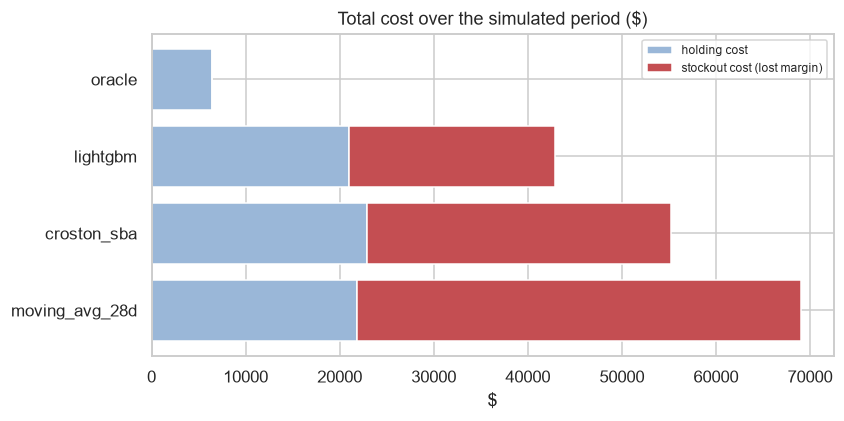

In [5]:
tg = with_costs(at_target(res[res["level"] == "all"]))
cols = ["method", "fill_rate_units", "fill_rate_revenue", "avg_inventory_value", "holding_cost", "stockout_cost", "total_cost"]
cost_summary = tg[cols].sort_values("total_cost").round(4).reset_index(drop=True)
show_table(cost_summary)

best_base = tg[tg["method"].isin(base_methods)].sort_values("total_cost")["method"].iloc[0]
cb = tg.loc[tg["method"] == best_base, "total_cost"].iloc[0]
cl = tg.loc[tg["method"] == "lightgbm", "total_cost"].iloc[0]
co = tg.loc[tg["method"] == "oracle", "total_cost"].iloc[0]
print(f"Best baseline at the target service level: {best_base}")
print(f"Total cost: baseline {cb:,.0f} -> lightgbm {cl:,.0f} ({100 * (cb - cl) / cb:+.1f}% saving), oracle {co:,.0f}")
if cb > co:
    print(f"Share of the oracle gap closed by LightGBM: {100 * (cb - cl) / (cb - co):.1f}%")

order = cost_summary["method"].tolist()
fig, ax = plt.subplots(figsize=(8, 3.8))
d = cost_summary.set_index("method").loc[order]
ax.barh(order, d["holding_cost"], color="#9ab7d8", label="holding cost")
ax.barh(order, d["stockout_cost"], left=d["holding_cost"], color="#c44e52", label="stockout cost (lost margin)")
ax.set(title="Total cost over the simulated period ($)", xlabel="$"); ax.legend(fontsize=8); ax.invert_yaxis()
save(fig, "28_cost_breakdown"); plt.show()

## 5. By segment

Where does the saving come from? Same comparison (best baseline vs LightGBM, target service level) for each segment. The fill rates are shown so you can see whether a saving comes with a service difference.

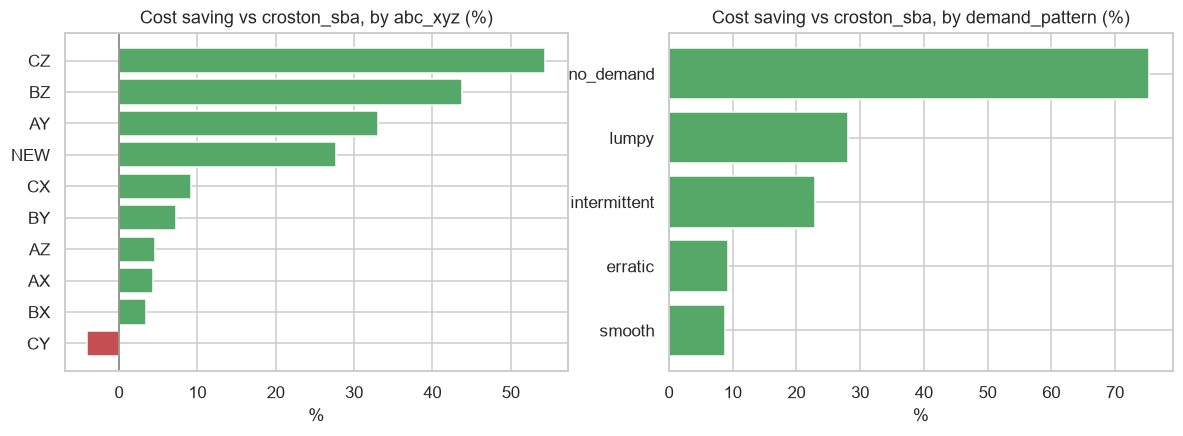

In [6]:
def seg_compare(level):
    d = with_costs(at_target(res[res["level"] == level]))
    b = d[d["method"] == best_base].set_index("group")
    l = d[d["method"] == "lightgbm"].set_index("group")
    o = d[d["method"] == "oracle"].set_index("group")
    out = pd.DataFrame({
        "n_series": l["n_series"], "base_total_cost": b["total_cost"], "lgbm_total_cost": l["total_cost"],
        "oracle_total_cost": o["total_cost"], "base_fill": b["fill_rate_revenue"], "lgbm_fill": l["fill_rate_revenue"],
        "base_inventory": b["avg_inventory_value"], "lgbm_inventory": l["avg_inventory_value"]})
    out["cost_saving_pct"] = 100 * (out["base_total_cost"] - out["lgbm_total_cost"]) / out["base_total_cost"]
    out["holding_saving"] = b["holding_cost"] - l["holding_cost"]
    out["stockout_saving"] = b["stockout_cost"] - l["stockout_cost"]
    out.insert(0, "group", out.index)
    out.insert(0, "level", level)
    return out.reset_index(drop=True)

by_seg = pd.concat([seg_compare(l) for l in ["abc", "xyz", "abc_xyz", "demand_pattern", "cat_id", "store_id"]], ignore_index=True).round(4)
show_table(by_seg)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, level in zip(axes, ["abc_xyz", "demand_pattern"]):
    d = by_seg[by_seg["level"] == level].sort_values("cost_saving_pct")
    ax.barh(d["group"], d["cost_saving_pct"], color=["#55a868" if v >= 0 else "#c44e52" for v in d["cost_saving_pct"]])
    ax.axvline(0, color="grey", lw=1); ax.set(title=f"Cost saving vs {best_base}, by {level} (%)", xlabel="%", ylabel="")
save(fig, "29_saving_by_segment"); plt.show()

## 6. Sensitivity to the cost assumptions

The unit cost, holding rate and stockout penalty are guesses. If the conclusion holds across reasonable values, it is more trustworthy. Each cell is the total-cost saving of LightGBM vs the best baseline, at the target service level.

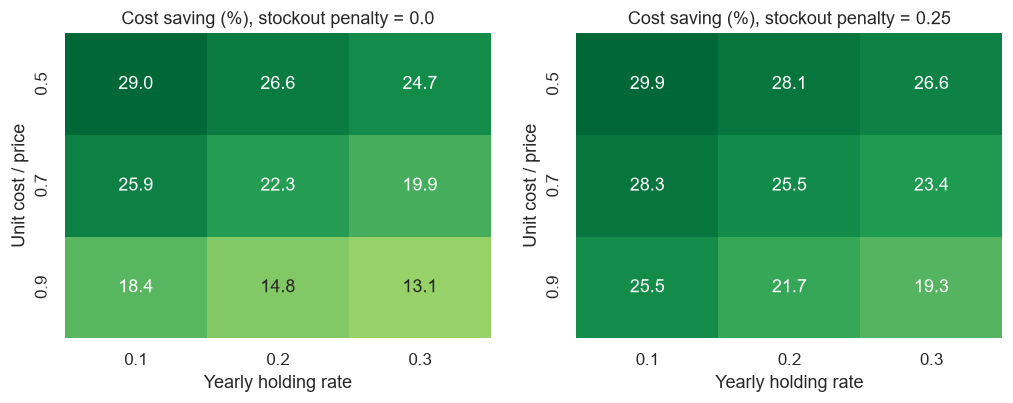

Saving ranges from 13.1% to 29.9% across the grid.


In [7]:
base_row = at_target(res[res["level"] == "all"]).query("method == @best_base")
lgb_row = at_target(res[res["level"] == "all"]).query("method == 'lightgbm'")
rows = []
for pen in [0.0, 0.25]:
    for ratio in [0.5, 0.7, 0.9]:
        for rate in [0.10, 0.20, 0.30]:
            cb_ = with_costs(base_row, ratio, rate, pen)["total_cost"].iloc[0]
            cl_ = with_costs(lgb_row, ratio, rate, pen)["total_cost"].iloc[0]
            rows.append({"stockout_penalty": pen, "cost_ratio": ratio, "holding_rate": rate,
                         "baseline_cost": cb_, "lgbm_cost": cl_, "saving_pct": 100 * (cb_ - cl_) / cb_})
sens = pd.DataFrame(rows).round(3)
show_table(sens)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, pen in zip(axes, [0.0, 0.25]):
    p_ = sens[sens["stockout_penalty"] == pen].pivot(index="cost_ratio", columns="holding_rate", values="saving_pct")
    sns.heatmap(p_, annot=True, fmt=".1f", cmap="RdYlGn", center=0, cbar=False, ax=ax)
    ax.set(title=f"Cost saving (%), stockout penalty = {pen}", xlabel="Yearly holding rate", ylabel="Unit cost / price")
save(fig, "30_cost_sensitivity"); plt.show()
print("Saving ranges from {:.1f}% to {:.1f}% across the grid.".format(sens["saving_pct"].min(), sens["saving_pct"].max()))

## 7. Replenishment plan (for the web)

The plan a planner would receive on the last forecast date: for each item-store series, the forecast demand over the next lead time + review period, the **safety stock** (the extra stock above the forecast to reach the target service level), the **order-up-to level** and the **reorder point** (the stock level at which a continuous-review system would trigger an order, based on lead-time demand). The dispersion column lets the web recompute these numbers for another service level. `actual_cover_demand` is what really happened, because this is a backtest.

In [8]:
plan["safety_stock_value"] = (plan["safety_stock"] * plan["price"] * config.INV_COST_RATIO).round(2)
plan["order_up_to_value"] = (plan["order_up_to"] * plan["price"] * config.INV_COST_RATIO).round(2)
plan = plan.sort_values("safety_stock_value", ascending=False).reset_index(drop=True)
show_table(plan)

ss = plan.groupby("abc_xyz").agg(n_series=("series_id", "count"), safety_stock_value=("safety_stock_value", "sum")).reset_index()
ss["pct_of_safety_stock_value"] = (100 * ss["safety_stock_value"] / ss["safety_stock_value"].sum()).round(1)
print("Where the safety stock money sits:")
show_table(ss.sort_values("safety_stock_value", ascending=False))

Where the safety stock money sits:


In [9]:
equal_service = eq.copy()
tradeoff = r.round(4)[["method", "alpha", "n_series", "fill_rate_units", "fill_rate_revenue", "avg_inventory_value",
                       "holding_cost", "stockout_cost", "total_cost"]]
saved = []
for df, name in [(plan, "replenishment_plan"), (tradeoff, "inventory_tradeoff"), (cost_summary, "inventory_cost_summary"),
                 (by_seg, "inventory_by_segment"), (equal_service, "inventory_equal_service"),
                 (sens, "inventory_sensitivity"), (assump, "inventory_assumptions_web")]:
    saved += save_table(df, name)
print("Saved for the web and for reuse:")
for p in saved:
    print("  ", p.relative_to(config.ROOT))

Saved for the web and for reuse:
   reports\tables\replenishment_plan.csv
   dashboard\data\replenishment_plan.json
   reports\tables\inventory_tradeoff.csv
   dashboard\data\inventory_tradeoff.json
   reports\tables\inventory_cost_summary.csv
   dashboard\data\inventory_cost_summary.json
   reports\tables\inventory_by_segment.csv
   dashboard\data\inventory_by_segment.json
   reports\tables\inventory_equal_service.csv
   dashboard\data\inventory_equal_service.json
   reports\tables\inventory_sensitivity.csv
   dashboard\data\inventory_sensitivity.json
   reports\tables\inventory_assumptions_web.csv
   dashboard\data\inventory_assumptions_web.json


## 8. Key findings (fill in after running on the real M5 data)

Write 6-8 bullets with numbers from your own tables, and state the assumptions next to every number:

- **Headline at equal service:** how much less inventory does LightGBM need to reach the same service as the best baseline? Or how many points of extra demand does it serve with the same stock?
- **Cost view:** what is the total-cost saving at the target service level, and how much of the gap to the oracle does it close? Is the saving mostly lower holding cost, fewer stockouts, or both?
- **Robustness:** across the sensitivity grid, does the saving stay positive? What is its range?
- **Where it matters:** which ABC-XYZ cells and demand patterns drive the saving? Are there segments with no benefit? (Notebook 03 found little gain for C items, so check whether the inventory view agrees.)
- **Safety stock:** where does the safety-stock money sit (which classes)? What does this suggest for service-level policy by class?
- **Limits:** no real costs, stock or lead times; one lead time and review period; forecasts refreshed monthly; lost sales only; independent series (no shared capacity); two simulated 28-day windows. Say this plainly.

**CV wording (only with your own numbers):** *"Built a forecast-driven inventory simulation on Walmart M5 data; at equal service level, the LightGBM forecast needed X% less inventory than a moving-average baseline (assumed 7-day lead time, weekly ordering)."*

**Next (notebook 05 and the web):** export the final tables as JSON and build the interactive dashboard.

*(Replace this cell with your own findings.)*